In [1]:
#analysis
import pandas as pd

df = pd.read_csv("Wifi7Tests.csv")

print(df.columns)
print(df.shape)

#======================================================================
filtered = df[(df["Environment"] == "Home-LOS") & (df["Mode"] == "Standard") & (df["Connection"] == "Wireless") & (df["PrimaryBand"].isin(["2.4GHz", "5GHz", "6GHz"]))
]
#======================================================================

data = filtered[["Distance", "PrimaryBand", "Run", "Throughput_Mbps"]]

print(data.shape)

print("Distances:")
print(sorted(data["Distance"].unique()))

print("Bands:")
print(data["PrimaryBand"].unique())

data.to_csv("wifi_data.csv", index=False)

print(data.groupby(["Distance", "PrimaryBand"]).size())

groups = data.groupby( ["Distance", "PrimaryBand"] )

#=========================================================================
summary = groups["Throughput_Mbps"].agg(["count", "mean", "std"]).reset_index()

summary.columns = ["Distance", "Band", "N", "Mean", "SD"]
summary["Mean"] = summary["Mean"].round(2)
summary["SD"] = summary["SD"].round(2)
print(summary)

summary.to_csv("wifi_summary.csv", index=False)

Index(['Timestamp', 'Environment', 'Scenario', 'Mode', 'PrimaryChannel',
       'PrimaryBand', 'PrimaryWidth_MHz', 'PrimaryLinkRate_Mbps',
       'SecondaryChannel', 'SecondaryBand', 'SecondaryWidth_MHz',
       'SecondaryLinkRate_Mbps', 'PrimaryCCI', 'PrimaryACI',
       'PrimaryNeighbors', 'SecondaryCCI', 'SecondaryACI',
       'SecondaryNeighbors', 'Streams', 'Throughput_Mbps', 'Retransmits',
       'Run', 'Distance', 'Material', 'PartitionAmount', 'PartitionThickness',
       'Connection', 'PrimaryRSSI', 'SecondaryRSSI'],
      dtype='str')
(779, 29)
(150, 4)
Distances:
[np.float64(1.5), np.float64(3.0), np.float64(4.5), np.float64(6.0), np.float64(12.0)]
Bands:
<StringArray>
['6GHz', '5GHz', '2.4GHz']
Length: 3, dtype: str
Distance  PrimaryBand
1.5       2.4GHz         10
          5GHz           10
          6GHz           10
3.0       2.4GHz         10
          5GHz           10
          6GHz           10
4.5       2.4GHz         10
          5GHz           10
          6GHz  

In [2]:
#Correlation
import pandas as pd

df = pd.read_csv("wifi_data.csv")

bands = ["2.4GHz", "5GHz", "6GHz"]

for band in bands:
    band_data = df[df["PrimaryBand"] == band]

    r = band_data["Distance"].corr(band_data["Throughput_Mbps"])

    print(f"{band}: r = {r:.4f}")

2.4GHz: r = -0.7697
5GHz: r = -0.6968
6GHz: r = 0.5443


    Distance    Band   N    Mean     SD
0        1.5  2.4GHz  10  103.47   1.65
1        1.5    5GHz  10  669.07  18.43
2        1.5    6GHz  10  529.34   9.83
3        3.0  2.4GHz  10  105.72   2.03
4        3.0    5GHz  10  620.95  10.16
5        3.0    6GHz  10  688.70  13.33
6        4.5  2.4GHz  10  103.96   2.69
7        4.5    5GHz  10  641.66  18.42
8        4.5    6GHz  10  629.88  33.46
9        6.0  2.4GHz  10   89.45   5.63
10       6.0    5GHz  10  531.45  33.78
11       6.0    6GHz  10  719.96  11.73
12      12.0  2.4GHz  10   85.59   7.93
13      12.0    5GHz  10  553.10  14.33
14      12.0    6GHz  10  687.97  13.97


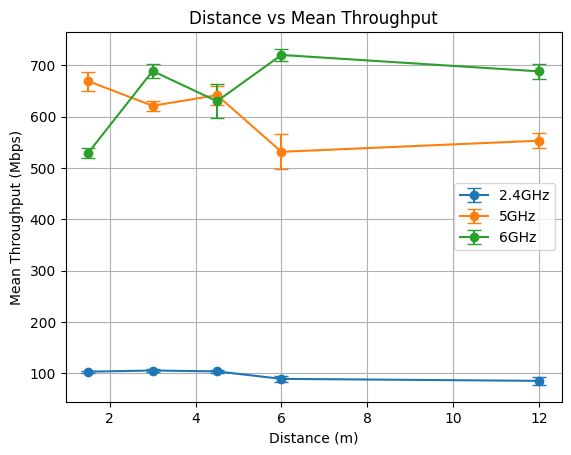

In [3]:
#Plot
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("wifi_summary.csv")

print(df)

for band in ["2.4GHz", "5GHz", "6GHz"]:
    band_data = df[df["Band"] == band]

    plt.errorbar(
        band_data["Distance"],
        band_data["Mean"],
        yerr=band_data["SD"],
        marker="o",
        capsize=5,
        label=band
    )

plt.xlabel("Distance (m)")
plt.ylabel("Mean Throughput (Mbps)")
plt.title("Distance vs Mean Throughput")
plt.legend()
plt.grid()

plt.show()

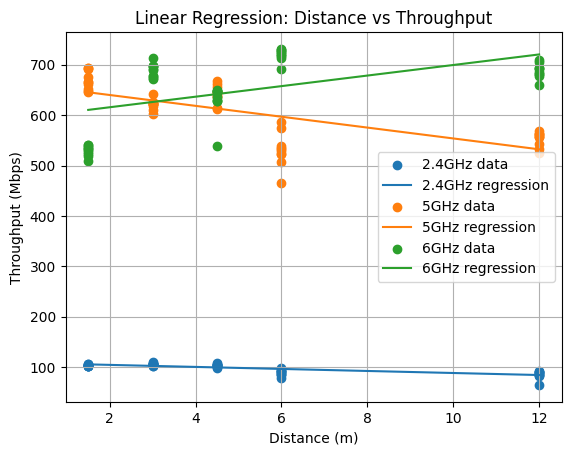

In [4]:
#Regression
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.linear_model import LinearRegression

df = pd.read_csv("wifi_data.csv")

bands = ["2.4GHz", "5GHz", "6GHz"]

for band in bands:
    band_data = df[df["PrimaryBand"] == band]

    X = band_data[["Distance"]]
    y = band_data["Throughput_Mbps"]

    model = LinearRegression()
    model.fit(X, y)

    # สร้างช่วงระยะทางสำหรับวาดเส้น regression
    x_line = np.linspace(
        X["Distance"].min(),
        X["Distance"].max(),
        100
    )

    # ทำนาย throughput บนเส้น
    y_line = model.predict(
        pd.DataFrame({"Distance": x_line})
    )

    # จุดข้อมูลจริง
    plt.scatter(
        X["Distance"],
        y,
        label=f"{band} data"
    )

    # เส้น regression
    plt.plot(
        x_line,
        y_line,
        label=f"{band} regression"
    )

plt.xlabel("Distance (m)")
plt.ylabel("Throughput (Mbps)")
plt.title("Linear Regression: Distance vs Throughput")
plt.legend()
plt.grid()

plt.show()